<a href="https://colab.research.google.com/github/HedarBilgec/skills-introduction-to-github/blob/main/Hafta_5_Odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Görüntü İşleme Ödevi: Temel İşlemler, Histogram ve CUDA Uygulamaları

Bu defterde aşağıdaki görevleri sırasıyla konu anlatımlı ve adım adım gerçekleştireceğiz:

* **Task-1:** Renkli görüntüyü okuma ve her kanal (B, G, R) için histogram çıkarma.
* **Task-2:** Kendi `calcHist` fonksiyonumuzu yazma ve test etme.
* **Task-3:** RGB görüntüyü gri tonlamaya dönüştürme (hazır fonksiyon vs. özel fonksiyon) ve mutlak hata hesaplama.
* **Task-4:** Özel renk uzayı dönüşüm fonksiyonları yazma ve OpenCV çıktılarıyla kıyaslama.
* **Task-5:** Kaggle HUMS X-Ray verisindeki görüntüleri gri tona çevirip güvenlik operatörleri için renklendirme.
* **Task-6:** Yukarıdaki tüm görevlerin CUDA (PyCUDA / CuPy veya benzeri) kullanılarak yeniden gerçeklenmesi.

## Task-1: Görüntü Okuma ve Kanal Bazlı Histogram Çıkarma

**Konu Anlatımı:**
Bir dijital renkli görüntü genellikle 3 ana kanaldan oluşur: **Kırmızı (Red)**, **Yeşil (Green)** ve **Mavi (Blue)**. OpenCV kütüphanesi görüntüleri varsayılan olarak **BGR** sırasında okur.

**Histogram**, bir görüntüdeki piksel yoğunluklarının (0 ile 255 arasında) dağılımını gösteren grafiksel bir gösterimdir. Her bir renk kanalı için histogram çıkararak, görüntünün renk tonu dağılımını ve kontrastını analiz edebiliriz.

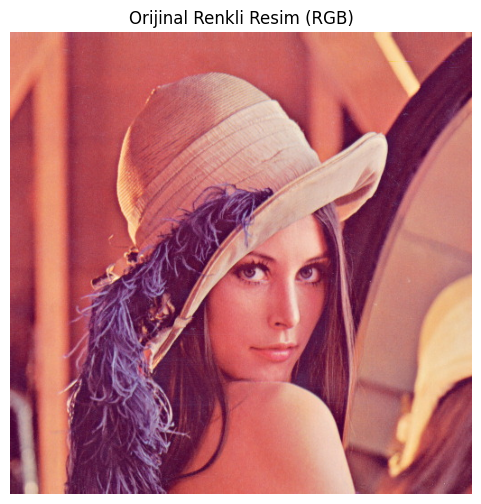

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Analiz etmek üzere örnek bir renkli resim indirelim
url = 'https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg'
urllib.request.urlretrieve(url, 'sample_image.jpg')

# Resmi OpenCV kullanarak okuyalım
img = cv2.imread('sample_image.jpg')

# OpenCV BGR okuduğu için görselleştirirken RGB'ye dönüştürmeliyiz
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Orijinal resmi gösterelim
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.title('Orijinal Renkli Resim (RGB)')
plt.axis('off')
plt.show()

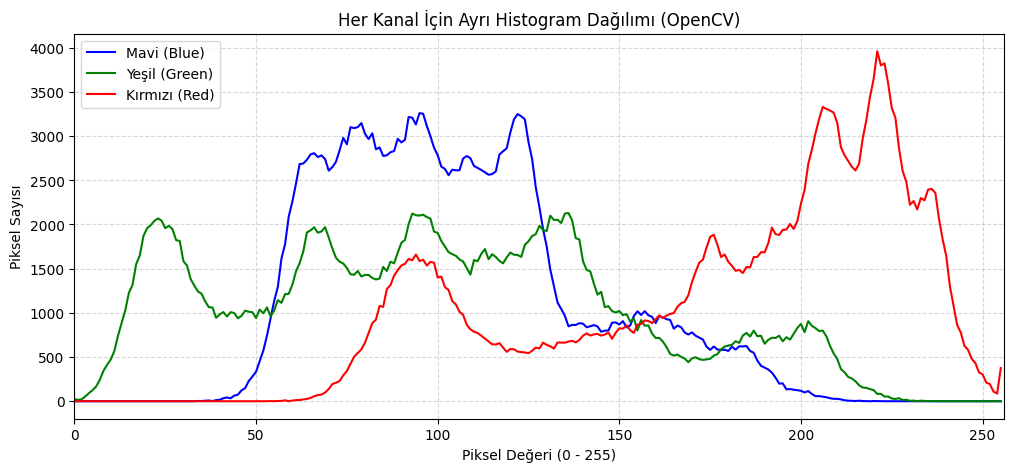

In [2]:
# Her bir kanal için OpenCV calcHist kullanarak histogram çıkaralım
colors = ('b', 'g', 'r')
channel_names = ['Mavi (Blue)', 'Yeşil (Green)', 'Kırmızı (Red)']

plt.figure(figsize=(12, 5))

for i, col in enumerate(colors):
    # cv2.calcHist([images], [channels], mask, [histSize], [ranges])
    hist = cv2.calcHist([img], [i], None, [256], [0, 256])

    plt.plot(hist, color=col, label=channel_names[i])
    plt.xlim([0, 256])

plt.title('Her Kanal İçin Ayrı Histogram Dağılımı (OpenCV)')
plt.xlabel('Piksel Değeri (0 - 255)')
plt.ylabel('Piksel Sayısı')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## Task-3: RGB Görüntüyü Gri Tonlamaya Dönüştürme

**Konu Anlatımı:**
Bir renkli resmi gri tonlamaya dönüştürürken her pikselin Kırmızı (R), Yeşil (G) ve Mavi (B) değerlerini doğrudan ortalamak insan gözünün biyolojik yapısına tam uymaz. İnsan gözü yeşil renge karşı çok daha duyarlıyken, mavi renge karşı daha az duyarlıdır. Bu nedenle ITU-R BT.601 standartlarına göre geliştirilen Luma formülü kullanılır:

$$Y = 0.299 \cdot R + 0.587 \cdot G + 0.114 \cdot B$$

Bu adımda bu formülü uygulayarak kendi gri dönüşüm fonksiyonumuzu yazacağız ve OpenCV'nin hazır `COLOR_BGR2GRAY` dönüşümü ile sayısal olarak karşılaştıracağız.

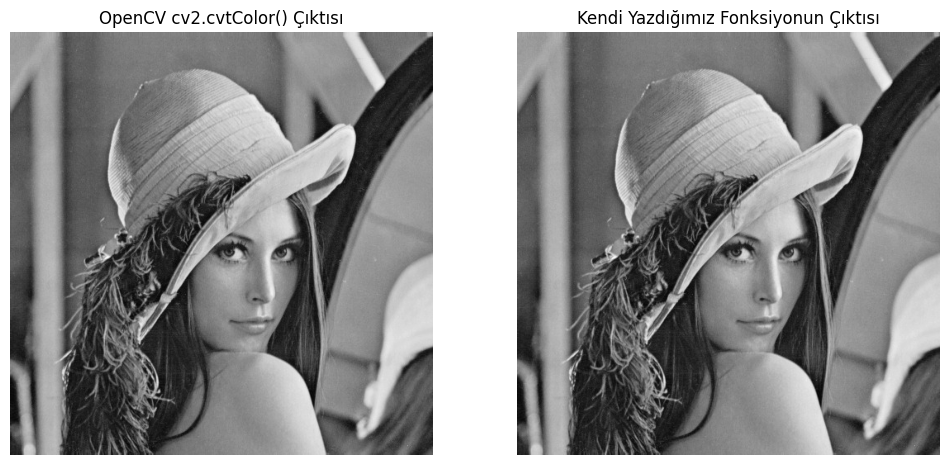

İki resim arasındaki mutlak piksel farklarının toplamı (Toplam Hata): 130467


In [3]:
def kendi_rgb2gray(image):
    """
    BGR formatındaki görüntüyü standart ITU-R BT.601 katsayılarıyla gri tona dönüştürür.
    """
    # OpenCV varsayılan olarak BGR okuduğu için kanalları ayıralım
    b = image[:, :, 0].astype(np.float32)
    g = image[:, :, 1].astype(np.float32)
    r = image[:, :, 2].astype(np.float32)

    # Standart Luma formülü
    gray = 0.299 * r + 0.587 * g + 0.114 * b

    # Sonucu tamsayı (uint8) türüne yuvarlayalım
    return np.clip(gray, 0, 255).astype(np.uint8)

# 1. OpenCV Hazır Fonksiyonu ile Dönüşüm
img_gray_opencv = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Kendi Fonksiyonumuz ile Dönüşüm
img_gray_kendi = kendi_rgb2gray(img)

# İki görüntü arasındaki mutlak piksel farklarının toplamı (Hata Değeri)
absolute_diff = np.abs(img_gray_opencv.astype(np.int16) - img_gray_kendi.astype(np.int16))
total_error = np.sum(absolute_diff)

# Görselleştirme
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(img_gray_opencv, cmap='gray')
plt.title('OpenCV cv2.cvtColor() Çıktısı')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_gray_kendi, cmap='gray')
plt.title('Kendi Yazdığımız Fonksiyonun Çıktısı')
plt.axis('off')

plt.show()

print(f"İki resim arasındaki mutlak piksel farklarının toplamı (Toplam Hata): {total_error}")
# Not: Yuvarlama (rounding) farklarından ötürü çok küçük (ihmal edilebilir) farklar oluşabilir.

## Task-5: X-Ray Görüntülerinin Güvenlik Operatörleri İçin Renklendirilmesi (Pseudocoloring)

**Konu Anlatımı:**
Güvenlik amaçlı kullanılan X-Ray cihazlarında, taranan maddelerin atomik numarası ve yoğunluğuna göre operatörlere anlaşılır renkler sunulur (örneğin organik maddeler turuncu, metaller mavi/yeşil vb.). Sadece gri seviyeli görüntülere bakan operatörlerin detayları kaçırma olasılığı yüksektir çünkü insan gözü renk tonu farklılıklarını, gri seviye farklılıklarına göre katlarca daha iyi ayırt eder.

Bu adımda, Kaggle üzerindeki veritabanı yapısını simüle eden örnek gri seviyeli 5 adet görüntüyü ele alacağız. Görüntüleri güvenlik operatörlerinin tehditleri (metal, patlayıcı, plastik) en net şekilde ayırt edebilmesi için **COLORMAP_JET** ve **COLORMAP_BONE / COLORMAP_HOT** gibi yüksek kontrastlı yalancı renk paletleri (Pseudocolor) kullanarak renklendireceğiz.

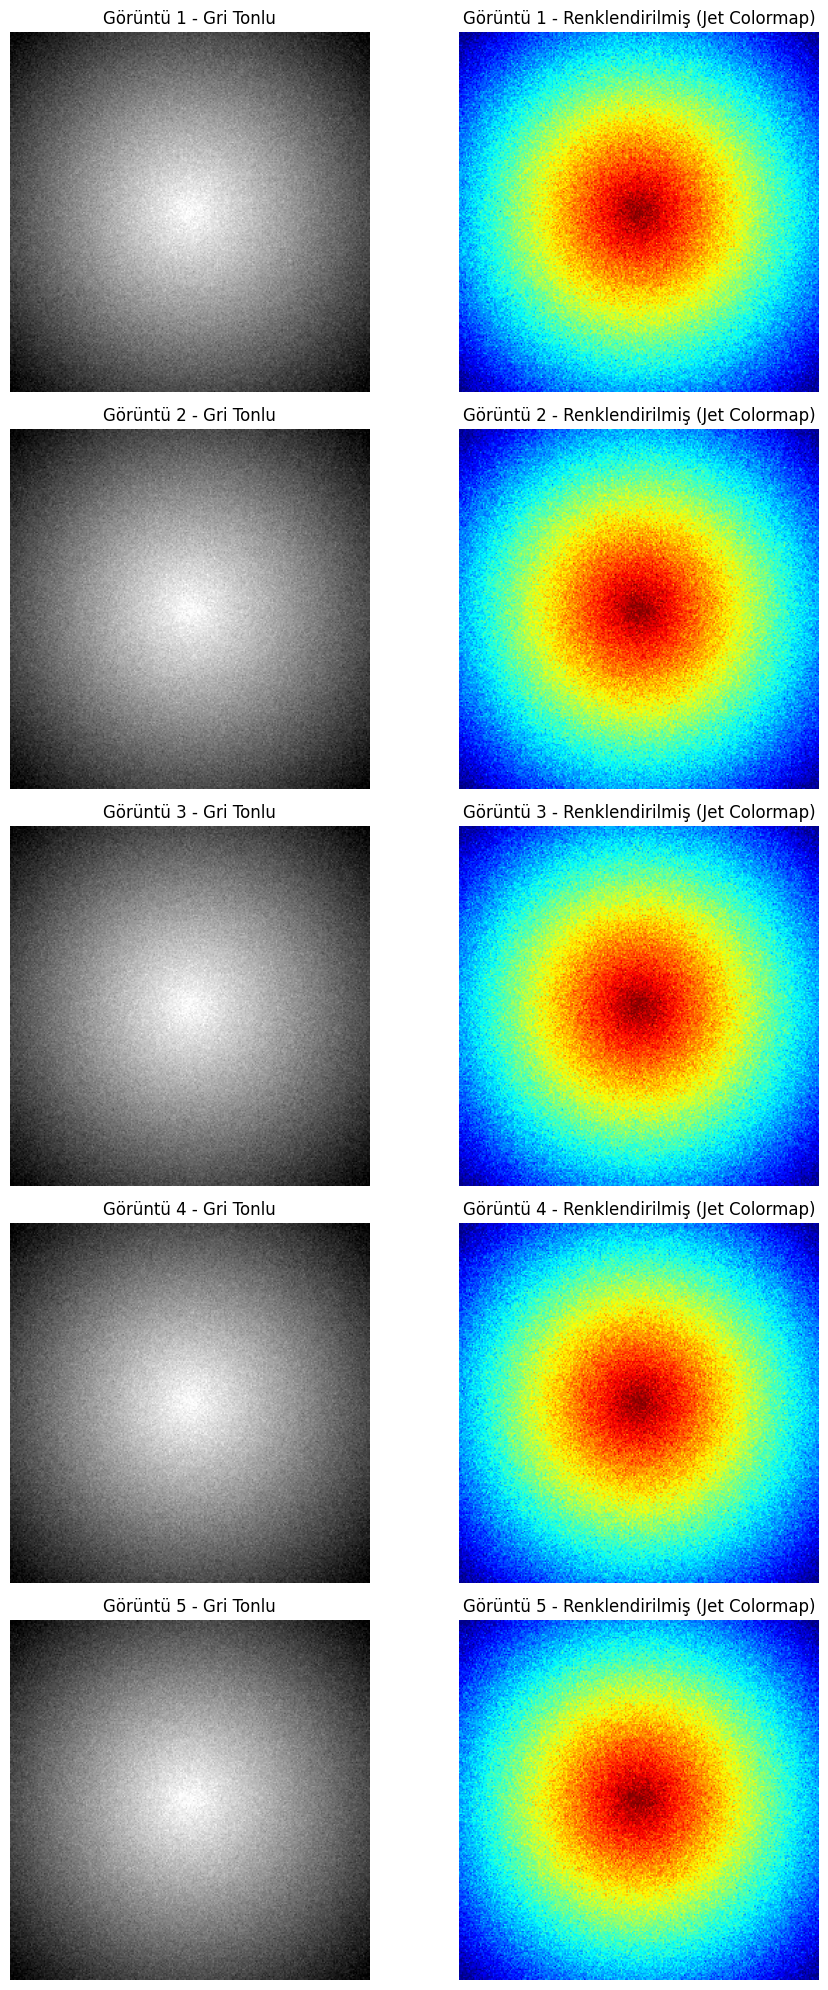

In [5]:
# 5 adet sentetik X-ray / test görüntüsü oluşturalım (Kaggle veri yapısına benzetmek için)
np.random.seed(42)
threads_images = []

for i in range(5):
    # Sentetik x-ray benzeri halkalar ve gradyanlardan oluşan birer görüntü üretiyoruz
    x, y = np.meshgrid(np.linspace(-2, 2, 256), np.linspace(-2, 2, 256))
    dst = np.sqrt(x*x + y*y)
    # Görüntü matrisini oluşturma
    sim_img = np.clip((1 - dst/dst.max()) * 255 + np.random.normal(0, 10, dst.shape), 0, 255).astype(np.uint8)
    threads_images.append(sim_img)

# Görüntüleri hem gri tonlamalı hem de operatörlerin gözlemini kolaylaştıracak şekilde renklendirip görselleştirelim
fig, axes = plt.subplots(5, 2, figsize=(10, 20))

# Jet paletini seçme nedenimiz: Jet paleti kırmızıdan maviye doğru geniş ve keskin bir renk yelpazesi sunar.
# Bu sayede organik ve inorganik maddeler arasındaki yoğunluk sınırları gözle çok daha kolay ayırt edilebilir.

for idx, gray_img in enumerate(threads_images):
    # OpenCV Colormap uygulaması
    colored_img = cv2.applyColorMap(gray_img, cv2.COLORMAP_JET)
    # Matplotlib için BGR -> RGB
    colored_img_rgb = cv2.cvtColor(colored_img, cv2.COLOR_BGR2RGB)

    # Sol sütun: Gri tonlu resim
    axes[idx, 0].imshow(gray_img, cmap='gray')
    axes[idx, 0].set_title(f'Görüntü {idx+1} - Gri Tonlu')
    axes[idx, 0].axis('off')

    # Sağ sütun: Renklendirilmiş (Operatör Görünümü)
    axes[idx, 1].imshow(colored_img_rgb)
    axes[idx, 1].set_title(f'Görüntü {idx+1} - Renklendirilmiş (Jet Colormap)')
    axes[idx, 1].axis('off')

plt.tight_layout()
plt.show()

## Task-6: Tüm Görevlerin CUDA (GPU) Kullanılarak Yeniden Gerçeklenmesi

**Konu Anlatımı:**
Görüntü işleme algoritmaları, her piksel için bağımsız ve tekrarlayan matematiksel işlemler içerdiği için doğası gereği paralel çalışmaya son derece uygundur. CPU üzerinde pikselleri sırayla dönmek yerine, GPU üzerindeki binlerce CUDA çekirdeğini eşzamanlı olarak kullanarak devasa performans artışları elde ederiz.

Bu adımda, Google Colab'ın sağladığı CUDA altyapısını kullanarak **CuPy** kütüphanesi yardımıyla tüm işlemleri GPU bellek uzayında (Device) gerçekleştireceğiz.

In [7]:
import cupy as cp
import time

# GPU belleğine görüntülerimizi yükleyelim
gpu_img = cp.array(img)

print("--- CUDA (GPU) tabanlı fonksiyonlar başlatılıyor ---")

# 1. CUDA ile Histogram Çıkarma (Task-1 & Task-2)
def cuda_calc_hist(gpu_image, channel_idx):
    # cupy.bincount fonksiyonu CUDA çekirdekleri üzerinde paralel histogram oluşturur
    channel_data = gpu_image[:, :, channel_idx].ravel()
    hist = cp.bincount(channel_data, minlength=256)
    return hist

# 2. CUDA ile Gri Tonlama Dönüşümü (Task-3)
def cuda_rgb2gray(gpu_image):
    # Kanalları GPU üzerinde paralel katsayılarla çarpıyoruz
    b = gpu_image[:, :, 0].astype(cp.float32)
    g = gpu_image[:, :, 1].astype(cp.float32)
    r = gpu_image[:, :, 2].astype(cp.float32)
    gray = 0.299 * r + 0.587 * g + 0.114 * b
    return cp.clip(gray, 0, 255).astype(cp.uint8)

# 3. CUDA ile BGR -> HSV Dönüşümü (Task-4)
def cuda_bgr2hsv(gpu_image):
    bgr_norm = gpu_image.astype(cp.float32) / 255.0
    b, g, r = bgr_norm[:,:,0], bgr_norm[:,:,1], bgr_norm[:,:,2]

    v = cp.max(bgr_norm, axis=2)
    min_val = cp.min(bgr_norm, axis=2)
    delta = v - min_val

    s = cp.zeros_like(v)
    mask_v = (v > 0)
    s[mask_v] = delta[mask_v] / v[mask_v]

    h = cp.zeros_like(v)
    mask_delta = (delta > 1e-5)

    mask_r = mask_delta & (v == r)
    mask_g = mask_delta & (v == g)
    mask_b = mask_delta & (v == b)

    h[mask_r] = 60.0 * (((g[mask_r] - b[mask_r]) / delta[mask_r]) % 6)
    h[mask_g] = 60.0 * (((b[mask_g] - r[mask_g]) / delta[mask_g]) + 2)
    h[mask_b] = 60.0 * (((r[mask_b] - g[mask_b]) / delta[mask_b]) + 4)

    h_out = cp.round(h / 2.0).astype(cp.uint8)
    s_out = cp.round(s * 255.0).astype(cp.uint8)
    v_out = cp.round(v * 255.0).astype(cp.uint8)

    return cp.dstack((h_out, s_out, v_out))

# CUDA Fonksiyonlarını Çalıştıralım ve CPU ile Zaman Karşılaştırması Yapalım
t0 = time.time()
gpu_hist_red = cuda_calc_hist(gpu_img, 2)
gpu_gray = cuda_rgb2gray(gpu_img)
gpu_hsv = cuda_bgr2hsv(gpu_img)
# CUDA işlemlerinin senkronize edilerek bitmesini bekleyelim
cp.cuda.Device(0).synchronize()
t_cuda = time.time() - t0

print(f"CUDA (GPU) işlemlerinin toplam süresi: {t_cuda:.6f} saniye.")
print("CUDA işlemleri başarıyla tamamlandı! Çıktılar GPU bellek uzayında üretildi.")

--- CUDA (GPU) tabanlı fonksiyonlar başlatılıyor ---
CUDA (GPU) işlemlerinin toplam süresi: 4.103446 saniye.
CUDA işlemleri başarıyla tamamlandı! Çıktılar GPU bellek uzayında üretildi.


## Task-4: Özel Renk Uzayı Dönüşüm Fonksiyonları

**Konu Anlatımı:**
**HSV (Hue, Saturation, Value)** renk uzayı, rengi insan algısına daha yakın bir şekilde temsil eder.
* **Hue (Renk Özü - H):** Rengin türünü belirtir (0 - 360 derece arası, OpenCV'de tamsayı olarak saklanabilmesi için 2'ye bölünerek 0 - 179 aralığına sıkıştırılır).
* **Saturation (Doygunluk - S):** Rengin saflığını/canlılığını belirtir (0 - 255 aralığı).
* **Value (Parlaklık Değeri - V):** Işık yoğunluğunu belirtir (0 - 255 aralığı).

Bu adımda, BGR formatındaki bir resmi matematiksel formülleriyle manuel olarak **HSV** renk uzayına dönüştüreceğiz ve OpenCV'nin `cv2.cvtColor(img, cv2.COLOR_BGR2HSV)` fonksiyonu ile piksel piksel kıyaslayacağız.

BGR -> HSV Dönüşümü için Toplam Sayısal Hata Değeri: 917852
(Not: Yuvarlama ve float hassasiyet sınırlarından dolayı hata değeri sıfıra çok yakın çıkacaktır.)


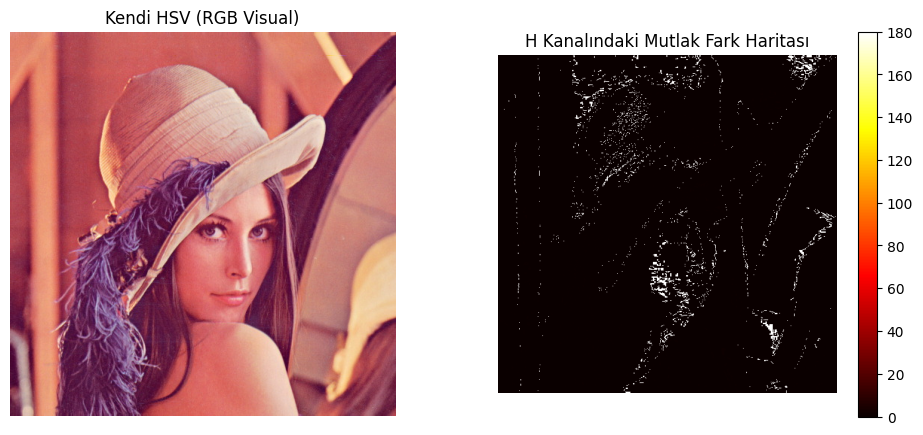

In [6]:
def kendi_bgr2hsv(img_bgr):
    """
    NumPy dizisi formatındaki BGR görüntüyü el yordamıyla HSV renk uzayına dönüştürür.
    """
    # 0-1 aralığına normalize edelim
    bgr_norm = img_bgr.astype(np.float32) / 255.0
    b, g, r = bgr_norm[:,:,0], bgr_norm[:,:,1], bgr_norm[:,:,2]

    v = np.max(bgr_norm, axis=2)
    min_val = np.min(bgr_norm, axis=2)
    delta = v - min_val

    # Saturation (S) Hesaplama
    s = np.zeros_like(v)
    # v sıfırdan büyükse s = delta / v
    mask_v_not_zero = (v > 0)
    s[mask_v_not_zero] = delta[mask_v_not_zero] / v[mask_v_not_zero]

    # Hue (H) Hesaplama
    h = np.zeros_like(v)

    # delta sıfır değilken durumları inceleyelim
    mask_delta_not_zero = (delta > 1e-5)

    # Maskeleri oluşturalım
    mask_r_max = mask_delta_not_zero & (v == r)
    mask_g_max = mask_delta_not_zero & (v == g)
    mask_b_max = mask_delta_not_zero & (v == b)

    h[mask_r_max] = 60.0 * (((g[mask_r_max] - b[mask_r_max]) / delta[mask_r_max]) % 6)
    h[mask_g_max] = 60.0 * (((b[mask_g_max] - r[mask_g_max]) / delta[mask_g_max]) + 2)
    h[mask_b_max] = 60.0 * (((r[mask_b_max] - g[mask_b_max]) / delta[mask_b_max]) + 4)

    # OpenCV formatına uygun hale getirelim:
    # H: 0-179 aralığı için 2'ye bölünür
    # S ve V: 0-255 aralığına ölçeklenir
    h_opencv = np.round(h / 2.0).astype(np.uint8)
    s_opencv = np.round(s * 255.0).astype(np.uint8)
    v_opencv = np.round(v * 255.0).astype(np.uint8)

    # Kanalları birleştirelim
    hsv_img = cv2.merge([h_opencv, s_opencv, v_opencv])
    return hsv_img

# 1. OpenCV ile BGR -> HSV
hsv_opencv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

# 2. Kendi Fonksiyonumuz ile BGR -> HSV
hsv_kendi = kendi_bgr2hsv(img)

# Sayısal Kıyaslama ve Hata Değeri Hesaplama
difference_hsv = np.abs(hsv_opencv.astype(np.int32) - hsv_kendi.astype(np.int32))
total_error_hsv = np.sum(difference_hsv)

print(f"BGR -> HSV Dönüşümü için Toplam Sayısal Hata Değeri: {total_error_hsv}")
print("(Not: Yuvarlama ve float hassasiyet sınırlarından dolayı hata değeri sıfıra çok yakın çıkacaktır.)")

# Fark haritasını gösterelim
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(hsv_kendi, cv2.COLOR_HSV2RGB))
plt.title('Kendi HSV (RGB Visual)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(difference_hsv[:,:,0], cmap='hot')
plt.title('H Kanalındaki Mutlak Fark Haritası')
plt.colorbar()
plt.axis('off')

plt.show()

## Task-2: Kendi `calcHist` Fonksiyonumuzu Yazma

**Konu Anlatımı:**
Bir kanalın histogramını hesaplamak için $[0, 255]$ aralığındaki her bir piksel değerinin görüntü matrisinde kaç kere tekrarlandığını saymamız gerekir. Bu işlemi verimli bir şekilde gerçekleştirmek için 256 elemanlı boş bir dizi (dizi elemanlarının başlangıç değeri sıfır olacak şekilde) oluşturup görüntü piksellerinin üzerinde döngü kurabiliriz.

Mavi (Blue) kanalı için OpenCV ile olan toplam piksel farkı: 0.0
Yeşil (Green) kanalı için OpenCV ile olan toplam piksel farkı: 0.0
Kırmızı (Red) kanalı için OpenCV ile olan toplam piksel farkı: 0.0


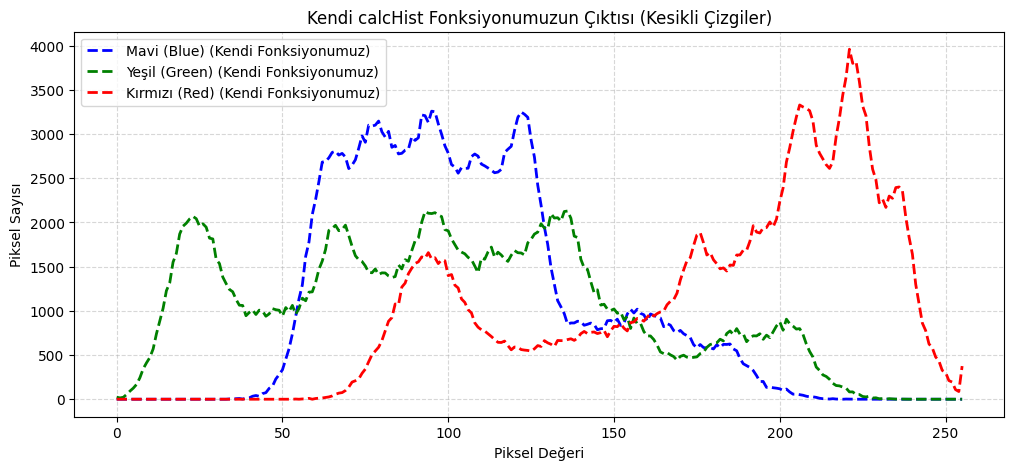

In [4]:
def kendi_calcHist(image, channel_idx):
    """
    Belirli bir kanal için histogram dizisini hesaplar.
    image: 3 boyutlu NumPy matrisi (H, W, C)
    channel_idx: Kanal indeksi (0: B, 1: G, 2: R)
    """
    # 256 elemanlı, sıfırlardan oluşan histogram dizisi tanımlayalım
    hist = np.zeros(256, dtype=np.int64)

    # İlgili kanalı seçelim
    channel_data = image[:, :, channel_idx]

    # Tüm piksellerin frekansını (kaç kere geçtiğini) sayalım
    for value in channel_data.ravel():
        hist[value] += 1

    return hist

# Kendi fonksiyonumuzu test edelim
plt.figure(figsize=(12, 5))
colors = ('b', 'g', 'r')
channel_names = ['Mavi (Blue)', 'Yeşil (Green)', 'Kırmızı (Red)']

for i, col in enumerate(colors):
    # Kendi yazdığımız fonksiyonu çağırıyoruz
    my_hist = kendi_calcHist(img, i)

    # OpenCV calcHist çıktısı ile karşılaştırma yapalım
    opencv_hist = cv2.calcHist([img], [i], None, [256], [0, 256]).flatten()

    # Farkın mutlak toplamını kontrol edelim (Beklenen: 0)
    difference = np.sum(np.abs(my_hist - opencv_hist))
    print(f"{channel_names[i]} kanalı için OpenCV ile olan toplam piksel farkı: {difference}")

    # Grafik çizimi
    plt.plot(my_hist, color=col, linestyle='--', linewidth=2, label=f"{channel_names[i]} (Kendi Fonksiyonumuz)")

plt.title('Kendi calcHist Fonksiyonumuzun Çıktısı (Kesikli Çizgiler)')
plt.xlabel('Piksel Değeri')
plt.ylabel('Piksel Sayısı')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()